# Two facing PET modules
Measured PE signals and first/second-interaction MC truth. Start by changing `CSV`.
Local depth runs from the glass face (0 mm) to the SiPM end (crystal length).
This baseline does **not** model polarization entanglement or random coincidences.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CSV = Path('length-15/events.csv')
df = pd.read_csv(CSV)
print(f'{len(df):,} generated events; {df.both_detected.sum():,} detected in both modules')
df[['EventID', 'A_npe_total', 'B_npe_total', 'A_truth_i1_type', 'B_truth_i1_type']].head()

100 generated events; 29 detected in both modules


,simulation_id,RunID,EventID,ThreadID,A_truth_n_primary_tracks,A_truth_n_interactions,A_truth_i1_track_id,A_truth_i1_process,A_truth_i1_type,A_truth_i1_pixel,...,B_npe_7_6,B_npe_7_7,B_detected,B_w,B_truth_total_edep_kev,both_detected,truth_distinct_pair,truth_plane_angle_deg,pixel_length_mm,pde
0,length-15,0,0,-1,1,3,2.0,compt,CS,A_pixel_1_2,...,0,0,True,0.516784,510.998964,True,True,70.960534,15.0,0.3
1,length-15,0,1,-1,1,2,2.0,compt,CS,A_pixel_2_4,...,0,0,True,0.321134,510.998964,True,True,49.095547,15.0,0.3
2,length-15,0,2,-1,0,0,NaN,NaN,NaN,NaN,...,10,17,True,0.718354,157.277631,False,False,NaN,15.0,0.3
3,length-15,0,3,-1,1,1,2.0,compt,CS,A_pixel_5_2,...,0,0,False,NaN,0.000000,False,False,NaN,15.0,0.3
4,length-15,0,4,-1,0,0,NaN,NaN,NaN,NaN,...,1,0,True,0.703412,510.998964,False,False,NaN,15.0,0.3


Select detected events. Keep the full dataframe so cuts can be changed without rereading it. The detection condition is same-event detection, not a timing-window selection.

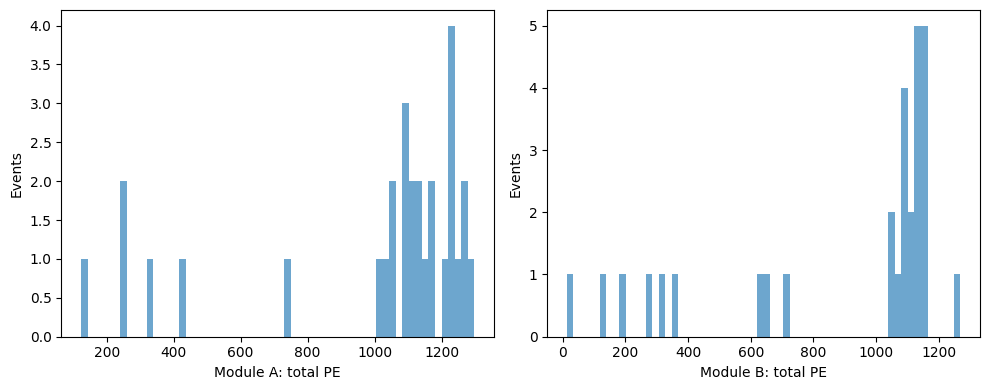

In [3]:
selected = df.loc[df.both_detected].copy()
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, module in zip(axes, ['A', 'B']):
    ax.hist(selected[f'{module}_npe_total'], bins=60, histtype='stepfilled', alpha=0.65)
    ax.set(xlabel=f'Module {module}: total PE', ylabel='Events')
fig.tight_layout()
plt.show()
